# 01 · Build the TNG50 jellyfish dataset

**Labels:** Cosmological Jellyfish citizen-science scores (Zinger et al. 2024, MNRAS 527, 8257), TNG50-1 supplementary catalogue `jellyfish.hdf5`.
Jellyfish = `ScoreAdjusted ≥ 0.8`. Clean non-jellyfish = `ScoreAdjusted ≤ 0.2` **and** the galaxy never scores ≥ 0.5 at any inspected epoch.

**Images:** rendered by us from gas and stellar particle cutouts fetched through the IllustrisTNG web API (one serial request per galaxy). We project along the simulation *z*-axis onto 128×128 pixels, with a field of view of 15 r½,★ (clipped to 20–80 ckpc/h), and smooth with σ = 1 px.

**Matched negatives (shortcut control):** a first sample with 'clean' negatives was strongly confounded. Non-jellyfish were far more gas-rich (median M_gas/M★ 1.86 vs 0.30), and 241 of them filled the frame with gas. A model could then separate the classes from gas *amount* alone. We therefore pair each jellyfish with the nearest clean non-jellyfish in (log M★, log M_gas/M★, snapshot), without replacement and at most one epoch per galaxy (`src/match_negatives.py`). Eight jellyfish whose bound-gas map is empty are dropped.

**Leakage control:** each galaxy is tracked across snapshots (a *branch*). Splits are made by branch, so the same galaxy never appears in both train and test.

> The download (≈1 h for 2,000 galaxies) can run from this notebook, or from a terminal with `python src/tng_data.py`. It resumes where it stopped.

In [1]:
import sys, warnings; from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, json
%matplotlib inline

In [2]:
import tng_data as T
cat = T.build_catalogue()
print(len(cat), 'inspected satellite-epochs at snapshots 67-99;', (cat.score>=0.8).sum(), 'jellyfish')
sample = pd.read_csv(ROOT/'data/processed/sample_matched.csv')   # built by src/match_negatives.py
sample.groupby('label').agg(n=('subhalo_id','size'), galaxies=('branch','nunique'), median_snap=('snap','median'))

48491 inspected satellite-epochs at snapshots 67-99; 3971 jellyfish


,n,galaxies,median_snap
label,,,
0,992,992,80.5
1,992,786,83.0


In [3]:
# Download + render (resumable). Skip this cell if the background job already finished.
RUN_FETCH = False
if RUN_FETCH:
    T.fetch_all(sample)   # or: python src/match_negatives.py (selection + matching + download)

In [4]:
from data import load_metadata, make_splits, load_maps, to_image, physical_masks
df = make_splits(load_metadata())
df.to_csv(ROOT/'data/processed/splits.csv', index=False)
pd.crosstab(df.split, df.label, margins=True)

label,0,1,All
split,,,
test,149,148,297
train,694,696,1390
val,149,148,297
All,992,992,1984


,log_mstar,log_fgas,snap,gas_pix
label,,,,
0,9.09,-0.38,80.5,667.5
1,9.06,-0.53,83.0,1301.5


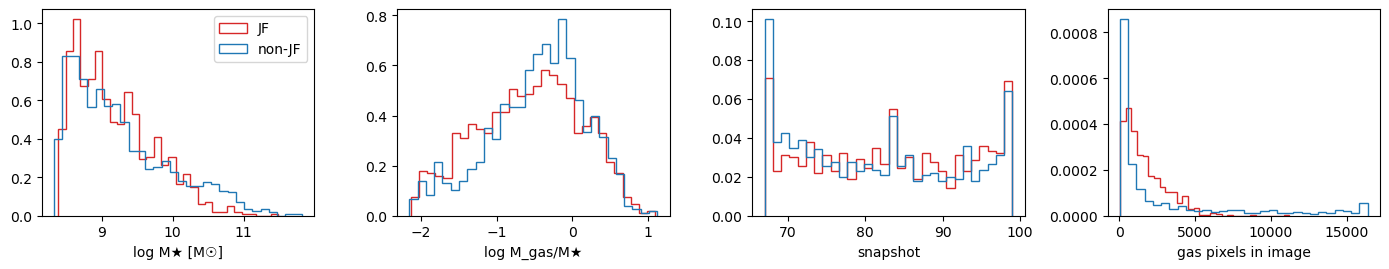

In [5]:
# Balance check: the matched sample should have similar mass, gas fraction and redshift distributions
from data import physical_masks
df['log_mstar'] = np.log10(df.mass_stars*1e10/0.6774); df['log_fgas'] = np.log10(df.mass_gas/df.mass_stars)
df['gas_pix'] = [physical_masks(r)[1].sum() for r in df.itertuples()]
fig, ax = plt.subplots(1, 4, figsize=(14, 2.8))
for a, c, l in zip(ax, ['log_mstar','log_fgas','snap','gas_pix'], ['log M★ [M☉]','log M_gas/M★','snapshot','gas pixels in image']):
    for lab, col in [(1,'C3'),(0,'C0')]:
        a.hist(df[df.label==lab][c], bins=30, histtype='step', color=col, label=['non-JF','JF'][lab], density=True)
    a.set_xlabel(l)
ax[0].legend(); plt.tight_layout(); plt.savefig(ROOT/'results/figures/fig_balance.pdf', bbox_inches='tight')
df.groupby('label')[['log_mstar','log_fgas','snap','gas_pix']].median().round(2)

## Example images and physical masks
Body = projected radius < 2 r½,★. Tail = gas pixels (log Σ_gas > −5.5) outside the body. These masks are the **ground truth** for scoring explanations in notebook 03.

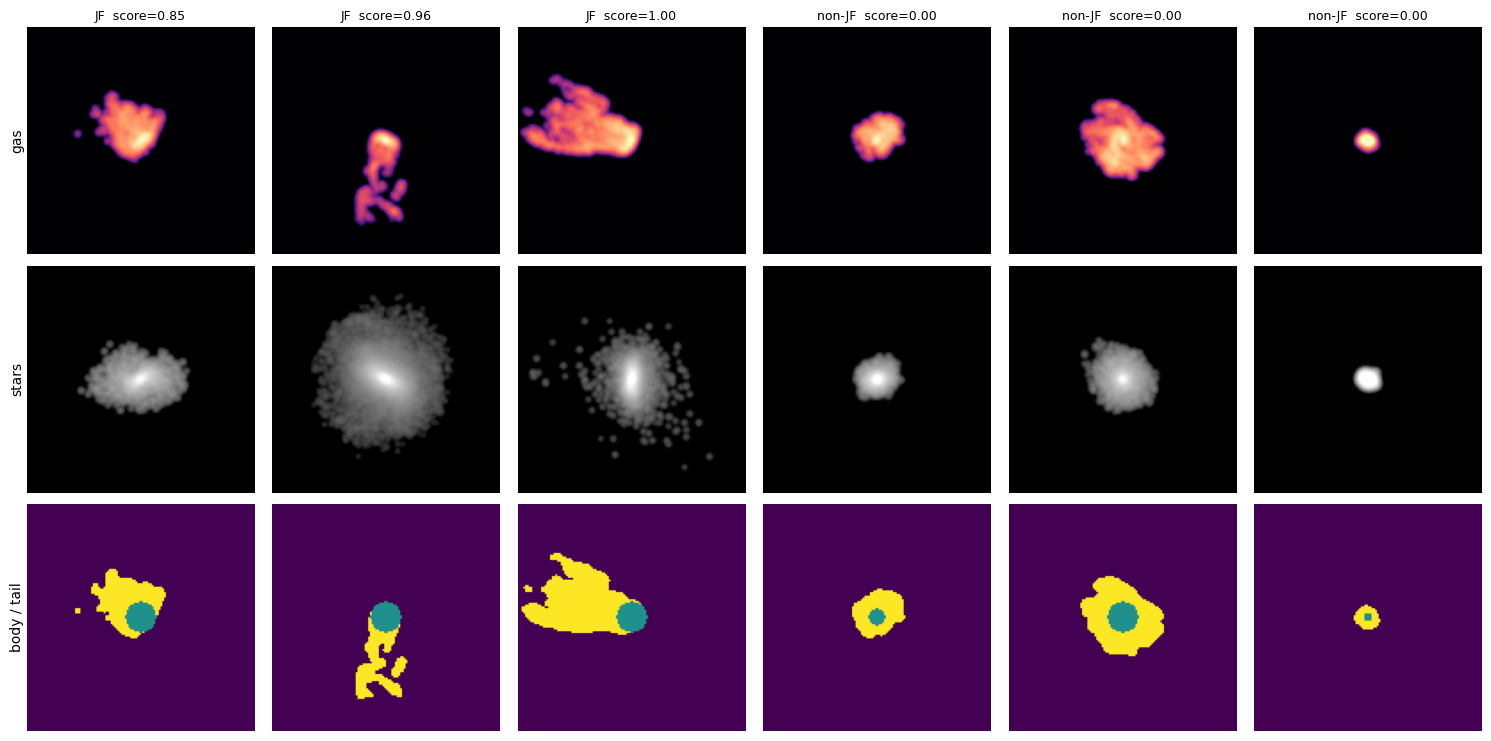

In [6]:
fig, ax = plt.subplots(3, 6, figsize=(15, 7.5))
ex = pd.concat([df[df.label==1].sample(3, random_state=1), df[df.label==0].sample(3, random_state=1)])
for j, r in enumerate(ex.itertuples()):
    gas, stars = load_maps(r.key); body, gasm, tail = physical_masks(r)
    ax[0,j].imshow(to_image(gas), cmap='magma', origin='lower'); ax[0,j].set_title(f"{'JF' if r.label else 'non-JF'}  score={r.score:.2f}", fontsize=9)
    ax[1,j].imshow(to_image(stars), cmap='gray', origin='lower')
    ax[2,j].imshow(body*1 + tail*2, cmap='viridis', origin='lower', vmin=0, vmax=2)
for a in ax.ravel(): a.axis('off')
ax[0,0].text(-10,64,'gas',rotation=90,va='center'); ax[1,0].text(-10,64,'stars',rotation=90,va='center'); ax[2,0].text(-10,64,'body / tail',rotation=90,va='center')
plt.tight_layout(); (ROOT/'results/figures').mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT/'results/figures/fig_examples.pdf', bbox_inches='tight')